# Validación Biológica del Mito «¿Existen los Mala Copas?»

**Objetivo científico:** Evaluar de forma cuantitativa y reproducible si existe fundamento biológico detrás del fenómeno popular conocido como «mala copa» (personas que alcanzan signos marcados de embriaguez con la misma cantidad de alcohol que otras toleran sin dificultad aparente).

**Marco farmacocinético de referencia:**
- Umbral de embriaguez marcada del proyecto: **120 mg/100 mL** (equivalente a `120 mg/dL` o `0.12% BAC`).
- La concentración de alcohol en sangre (**BAC**, por sus siglas en inglés) depende tanto de factores conductuales (dosis total ingerida y velocidad de consumo) como de factores fisiológicos reales: el volumen de **Agua Corporal Total (TBW)** determinado por sexo biológico, estatura, peso y masa magra asociada al entrenamiento físico, además de la variabilidad metabólica hepática individual (enzimas **ADH/ALDH**) y de absorción gástrica.

## Sección 1: Configuración, carga y prevención de fuga de datos (*data leakage*)

En esta sección cargamos el conjunto de datos generado en el Sprint 1 (`data/synthetic_bac_dataset.csv`), importamos las constantes compartidas desde `src/constants.py` y verificamos la integridad del esquema.

### ¿Por qué excluimos las variables `latent_*` del modelo predictivo?
Las columnas `latent_tbw_adj` (agua corporal total real individual ajustada), `latent_beta_eliminacion` (tasa real de depuración hepática ADH/ALDH) y `latent_f_abs` (fracción real de absorción gástrica) representan **estados biológicos internos no observables** sin pruebas clínicas de laboratorio. Incluirlas como variables de entrada (`X`) produciría **fuga de datos (*data leakage*)**, ya que el modelo usaría parámetros ocultos imposibles de conocer en un escenario real de consumo social. Por ello:
1. Se excluyen estrictamente de `FEATURE_COLS` mediante un `assert` explícito.
2. Se reservan únicamente para **auditar la biología subyacente** sobre los residuales del modelo en la Sección 4.

In [1]:
from pathlib import Path
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED)

# Configuración estética global de gráficas en español
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

# Resolución robusta de la raíz del proyecto (funciona desde notebooks/ o raíz del repo)
CWD = Path.cwd().resolve()
PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.constants import BAC_THRESHOLD_MG_100ML, DRINKS, TRAINING_LEVELS

DATA_PATH = PROJECT_ROOT / "data" / "synthetic_bac_dataset.csv"
df = pd.read_csv(DATA_PATH)

# Validación estructural
assert df.shape == (15_000, 12), f"Dimensiones inesperadas: {df.shape}"
assert df.isna().sum().sum() == 0, "Se detectaron valores nulos en el dataset."

FEATURE_COLS = [
    "sexo",
    "edad",
    "estatura_cm",
    "peso_kg",
    "nivel_entrenamiento",
    "horas_consumo",
    "gramos_alcohol",
    "velocidad_consumo_g_h",
]
TARGET_COL = "bac_mg_100ml"
LATENT_COLS = [
    "latent_tbw_adj",
    "latent_beta_eliminacion",
    "latent_f_abs",
]

# Prevención explícita de Data Leakage
assert not any(col.startswith("latent_") for col in FEATURE_COLS), (
    "Error crítico de Data Leakage: se detectó una columna latent_ en FEATURE_COLS."
)
assert set(FEATURE_COLS).isdisjoint(LATENT_COLS), "Conflicto entre features y latentes."
assert TARGET_COL not in FEATURE_COLS, "La variable objetivo no puede estar en FEATURE_COLS."

print(f"Dataset cargado correctamente: {df.shape[0]:,} filas x {df.shape[1]} columnas | 0 nulos")
print(f"Umbral de embriaguez de referencia: {BAC_THRESHOLD_MG_100ML:.1f} mg/100 mL (0.12% BAC)")
print("Verificación anti-leakage superada: ninguna variable latent_* está en FEATURE_COLS.")
display(df.dtypes.to_frame(name="Tipo de dato"))
display(df.head())

Dataset cargado correctamente: 15,000 filas x 12 columnas | 0 nulos
Umbral de embriaguez de referencia: 120.0 mg/100 mL (0.12% BAC)
Verificación anti-leakage superada: ninguna variable latent_* está en FEATURE_COLS.


,Tipo de dato
sexo,object
edad,int64
estatura_cm,float64
peso_kg,float64
nivel_entrenamiento,int64
horas_consumo,float64
gramos_alcohol,float64
velocidad_consumo_g_h,float64
bac_mg_100ml,float64
latent_tbw_adj,float64


,sexo,edad,estatura_cm,peso_kg,nivel_entrenamiento,horas_consumo,gramos_alcohol,velocidad_consumo_g_h,bac_mg_100ml,latent_tbw_adj,latent_beta_eliminacion,latent_f_abs
0,F,42,160.4,72.2,1,0.78,126.93,162.73,276.68,31.8670,10.0556,0.8857
1,M,45,169.9,63.6,2,1.28,188.64,147.38,329.60,39.2824,15.4476,0.9021
2,F,27,165.2,50.3,0,5.90,85.99,14.57,148.27,26.8443,13.8833,0.8910
3,F,29,163.6,58.3,0,5.68,95.17,16.76,194.23,28.5194,11.5759,0.9660
4,M,33,185.6,73.3,0,5.64,187.99,33.33,292.21,43.3206,10.2432,1.0000


## Sección 2: Análisis Exploratorio de Datos (EDA) con foco fisiológico

Analizamos la distribución de las variables observables y su relación empírica con `bac_mg_100ml`, prestando especial atención al umbral de **120 mg/100 mL** y a las diferencias por sexo biológico, masa corporal, nivel de entrenamiento físico y velocidad de ingesta.

In [2]:
# Estadísticas descriptivas de variables observables y objetivo
desc_table = df[FEATURE_COLS + [TARGET_COL]].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]].round(2)
display(desc_table)

# Resumen agrupado por sexo biológico y nivel de entrenamiento
df_eda = df.copy()
df_eda["sexo_etiqueta"] = df_eda["sexo"].map({"F": "Femenino (F)", "M": "Masculino (M)"})
training_label_map = {k: v["label"] for k, v in TRAINING_LEVELS.items()}
df_eda["entrenamiento_etiqueta"] = df_eda["nivel_entrenamiento"].map(training_label_map)

resumen_sexo = (
    df_eda.groupby("sexo_etiqueta")
    .agg(
        n=("bac_mg_100ml", "count"),
        peso_medio_kg=("peso_kg", "mean"),
        gramos_medios=("gramos_alcohol", "mean"),
        bac_medio=("bac_mg_100ml", "mean"),
        bac_mediana=("bac_mg_100ml", "median"),
        pct_sobre_120=("bac_mg_100ml", lambda s: (s >= BAC_THRESHOLD_MG_100ML).mean() * 100),
    )
    .round(2)
)
display(resumen_sexo)

,count,mean,std,min,25%,50%,75%,max
edad,15000.0,33.70,9.50,18.00,26.00,32.00,40.00,64.00
estatura_cm,15000.0,166.39,9.33,145.00,159.40,166.20,173.20,198.70
peso_kg,15000.0,68.21,13.34,35.70,58.60,67.30,76.60,133.90
nivel_entrenamiento,15000.0,1.14,1.10,0.00,0.00,1.00,2.00,3.00
horas_consumo,15000.0,3.25,1.59,0.50,1.86,3.23,4.63,6.00
gramos_alcohol,15000.0,110.99,63.71,0.01,55.96,111.70,166.32,220.00
velocidad_consumo_g_h,15000.0,50.31,54.45,0.00,17.15,34.04,61.26,425.42
bac_mg_100ml,15000.0,181.24,139.24,0.00,59.00,168.76,278.79,696.47


,n,peso_medio_kg,gramos_medios,bac_medio,bac_mediana,pct_sobre_120
sexo_etiqueta,,,,,,
Femenino (F),7507,62.91,111.00,217.54,210.88,67.70
Masculino (M),7493,73.51,110.98,144.87,138.12,54.42


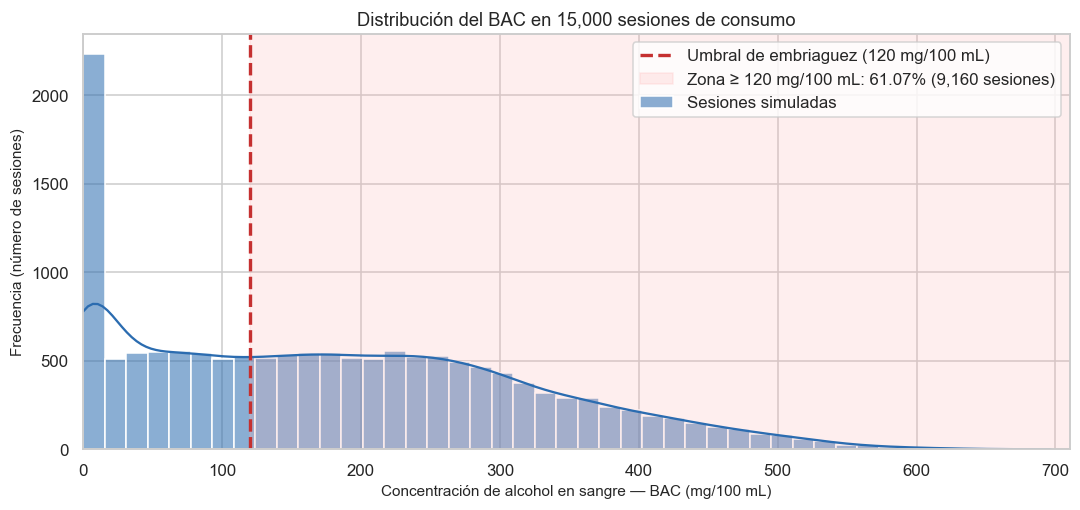

In [3]:
# Figura 1: Distribución de bac_mg_100ml con umbral de 120 mg/100 mL
pct_sobre_umbral = float((df[TARGET_COL] >= BAC_THRESHOLD_MG_100ML).mean() * 100)
n_sobre_umbral = int((df[TARGET_COL] >= BAC_THRESHOLD_MG_100ML).sum())

fig, ax = plt.subplots(figsize=(10, 4.8))
sns.histplot(
    data=df,
    x=TARGET_COL,
    bins=45,
    kde=True,
    color="#2b6cb0",
    alpha=0.55,
    edgecolor="white",
    ax=ax,
    label="Sesiones simuladas",
)
ax.axvline(
    BAC_THRESHOLD_MG_100ML,
    color="#c53030",
    linestyle="--",
    linewidth=2.2,
    label=f"Umbral de embriaguez ({BAC_THRESHOLD_MG_100ML:.0f} mg/100 mL)",
)
ax.axvspan(
    BAC_THRESHOLD_MG_100ML,
    df[TARGET_COL].max() * 1.02,
    color="#feb2b2",
    alpha=0.22,
    label=f"Zona ≥ {BAC_THRESHOLD_MG_100ML:.0f} mg/100 mL: {pct_sobre_umbral:.2f}% ({n_sobre_umbral:,} sesiones)",
)
ax.set_title("Distribución del BAC en 15,000 sesiones de consumo")
ax.set_xlabel("Concentración de alcohol en sangre — BAC (mg/100 mL)")
ax.set_ylabel("Frecuencia (número de sesiones)")
ax.set_xlim(0, df[TARGET_COL].max() * 1.02)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

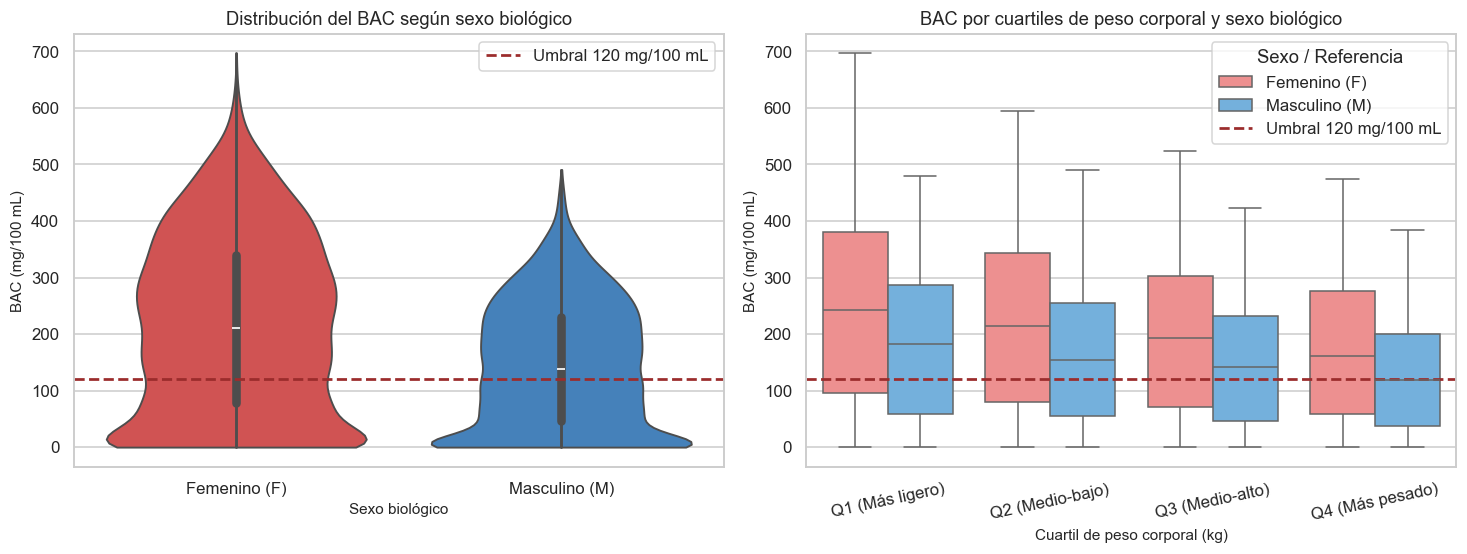

In [4]:
# Figura 2: Impacto del sexo biológico y del peso corporal (cuartiles) sobre el BAC
df_eda["cuartil_peso"] = pd.qcut(
    df_eda["peso_kg"],
    q=4,
    labels=["Q1 (Más ligero)", "Q2 (Medio-bajo)", "Q3 (Medio-alto)", "Q4 (Más pesado)"],
)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

sns.violinplot(
    data=df_eda,
    x="sexo_etiqueta",
    y=TARGET_COL,
    palette={"Femenino (F)": "#e53e3e", "Masculino (M)": "#3182ce"},
    inner="box",
    cut=0,
    ax=axes[0],
)
axes[0].axhline(
    BAC_THRESHOLD_MG_100ML,
    color="#9b2c2c",
    linestyle="--",
    linewidth=1.8,
    label=f"Umbral {BAC_THRESHOLD_MG_100ML:.0f} mg/100 mL",
)
axes[0].set_title("Distribución del BAC según sexo biológico")
axes[0].set_xlabel("Sexo biológico")
axes[0].set_ylabel("BAC (mg/100 mL)")
axes[0].legend(loc="upper right")

sns.boxplot(
    data=df_eda,
    x="cuartil_peso",
    y=TARGET_COL,
    hue="sexo_etiqueta",
    palette={"Femenino (F)": "#fc8181", "Masculino (M)": "#63b3ed"},
    ax=axes[1],
)
axes[1].axhline(
    BAC_THRESHOLD_MG_100ML,
    color="#9b2c2c",
    linestyle="--",
    linewidth=1.8,
    label=f"Umbral {BAC_THRESHOLD_MG_100ML:.0f} mg/100 mL",
)
axes[1].set_title("BAC por cuartiles de peso corporal y sexo biológico")
axes[1].set_xlabel("Cuartil de peso corporal (kg)")
axes[1].set_ylabel("BAC (mg/100 mL)")
axes[1].tick_params(axis="x", rotation=12)
axes[1].legend(title="Sexo / Referencia", loc="upper right")

plt.tight_layout()
plt.show()

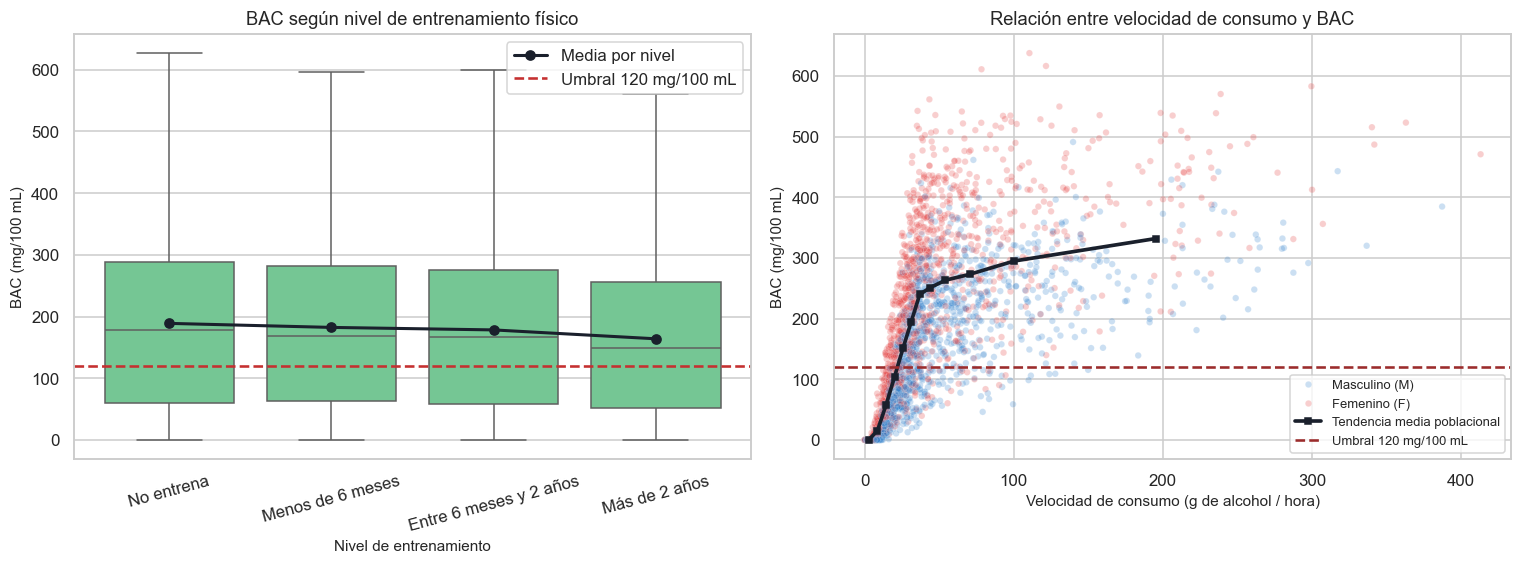

In [5]:
# Figura 3: Impacto escalonado del entrenamiento y velocidad de consumo
orden_entreno = [TRAINING_LEVELS[i]["label"] for i in sorted(TRAINING_LEVELS.keys())]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.3))

sns.boxplot(
    data=df_eda,
    x="entrenamiento_etiqueta",
    y=TARGET_COL,
    order=orden_entreno,
    color="#68d391",
    showfliers=False,
    ax=axes[0],
)
medias_entreno = df_eda.groupby("entrenamiento_etiqueta")[TARGET_COL].mean().reindex(orden_entreno)
axes[0].plot(
    range(len(orden_entreno)),
    medias_entreno.values,
    marker="o",
    color="#1a202c",
    linewidth=2.0,
    label="Media por nivel",
)
axes[0].axhline(
    BAC_THRESHOLD_MG_100ML,
    color="#c53030",
    linestyle="--",
    linewidth=1.7,
    label=f"Umbral {BAC_THRESHOLD_MG_100ML:.0f} mg/100 mL",
)
axes[0].set_title("BAC según nivel de entrenamiento físico")
axes[0].set_xlabel("Nivel de entrenamiento")
axes[0].set_ylabel("BAC (mg/100 mL)")
axes[0].tick_params(axis="x", rotation=15)
axes[0].legend(loc="upper right")

# Dispersión muestreada (para claridad visual) + tendencia por deciles de velocidad
muestra = df_eda.sample(n=2500, random_state=SEED)
sns.scatterplot(
    data=muestra,
    x="velocidad_consumo_g_h",
    y=TARGET_COL,
    hue="sexo_etiqueta",
    palette={"Femenino (F)": "#e53e3e", "Masculino (M)": "#3182ce"},
    alpha=0.25,
    s=18,
    ax=axes[1],
)
# Tendencia suavizada por cuantiles de velocidad de consumo
bins_vel = pd.qcut(df_eda["velocidad_consumo_g_h"], q=12, duplicates="drop")
tendencia_vel = (
    df_eda.groupby(bins_vel, observed=False)
    .agg(vel_media=("velocidad_consumo_g_h", "mean"), bac_medio=(TARGET_COL, "mean"))
)
axes[1].plot(
    tendencia_vel["vel_media"],
    tendencia_vel["bac_medio"],
    color="#1a202c",
    linewidth=2.4,
    marker="s",
    markersize=4,
    label="Tendencia media poblacional",
)
axes[1].axhline(
    BAC_THRESHOLD_MG_100ML,
    color="#9b2c2c",
    linestyle="--",
    linewidth=1.7,
    label=f"Umbral {BAC_THRESHOLD_MG_100ML:.0f} mg/100 mL",
)
axes[1].set_title("Relación entre velocidad de consumo y BAC")
axes[1].set_xlabel("Velocidad de consumo (g de alcohol / hora)")
axes[1].set_ylabel("BAC (mg/100 mL)")
axes[1].legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
plt.show()

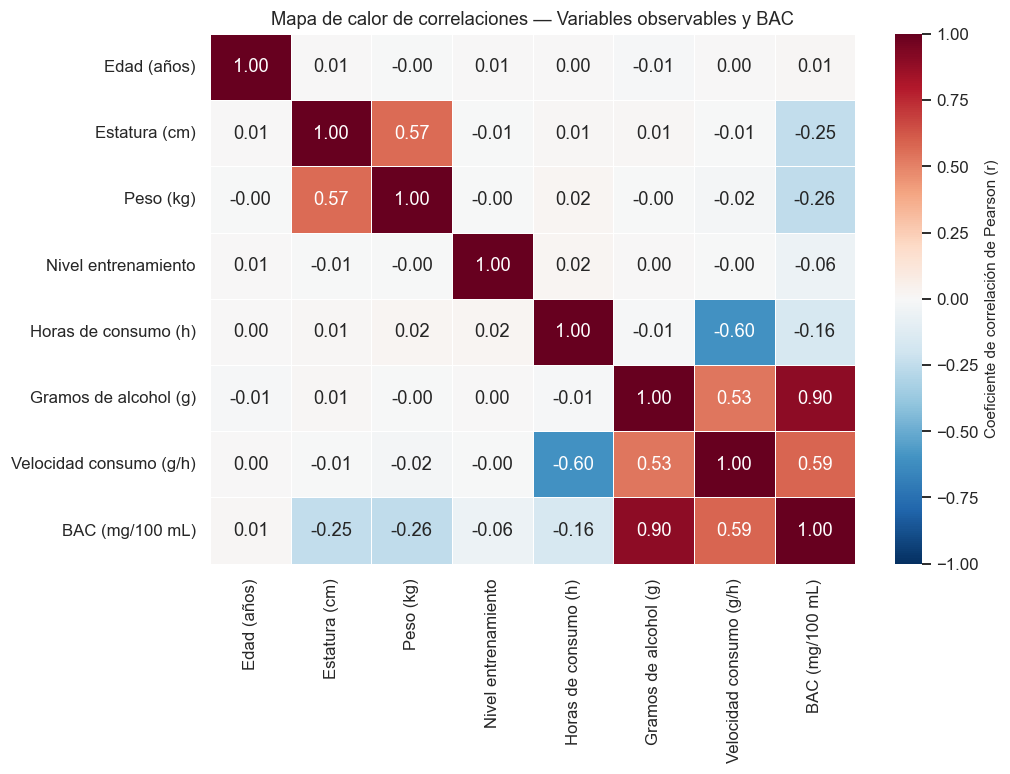

In [6]:
# Figura 4: Mapa de calor de correlaciones de variables numéricas observables con BAC
num_cols_corr = [
    "edad",
    "estatura_cm",
    "peso_kg",
    "nivel_entrenamiento",
    "horas_consumo",
    "gramos_alcohol",
    "velocidad_consumo_g_h",
    TARGET_COL,
]
etiquetas_corr = {
    "edad": "Edad (años)",
    "estatura_cm": "Estatura (cm)",
    "peso_kg": "Peso (kg)",
    "nivel_entrenamiento": "Nivel entrenamiento",
    "horas_consumo": "Horas de consumo (h)",
    "gramos_alcohol": "Gramos de alcohol (g)",
    "velocidad_consumo_g_h": "Velocidad consumo (g/h)",
    "bac_mg_100ml": "BAC (mg/100 mL)",
}
corr_matrix = df[num_cols_corr].rename(columns=etiquetas_corr).corr()

fig, ax = plt.subplots(figsize=(9.5, 7.2))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0.0,
    vmin=-1.0,
    vmax=1.0,
    linewidths=0.6,
    cbar_kws={"label": "Coeficiente de correlación de Pearson (r)"},
    ax=ax,
)
ax.set_title("Mapa de calor de correlaciones — Variables observables y BAC")
plt.tight_layout()
plt.show()

## Sección 3: Entrenamiento del modelo `RandomForestRegressor`

Dividimos los datos en entrenamiento (`80%`, `12,000` registros) y prueba (`20%`, `3,000` registros) conservando los índices originales para poder cruzar después las predicciones del conjunto de prueba con sus variables latentes ocultas.

Construimos un `Pipeline` completo de `scikit-learn` que encapsula:
1. **`ColumnTransformer`**: codificación `OneHotEncoder(handle_unknown="ignore", sparse_output=False)` para `sexo`, y paso directo (`"passthrough"`) para las 7 variables numéricas observables.
2. **`RandomForestRegressor`**: `n_estimators=150`, `max_depth=14`, `min_samples_leaf=4`, `random_state=42`, configuración que equilibra capacidad no lineal, generalización sin sobreajuste y un tamaño compacto del artefacto `.joblib` (`< 15 MB`) para inferencia rápida en el Sprint 3.

In [7]:
X = df[FEATURE_COLS].copy()
y = df[TARGET_COL].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

num_features = [c for c in FEATURE_COLS if c != "sexo"]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["sexo"]),
        ("num", "passthrough", num_features),
    ],
    remainder="drop",
)

rf_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=14,
    min_samples_leaf=4,
    random_state=SEED,
    n_jobs=-1,
)

pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", rf_model),
    ]
)

# Validación cruzada de 5 pliegues sobre entrenamiento
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_results = cross_validate(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
    },
    n_jobs=-1,
)

cv_r2_mean, cv_r2_std = float(cv_results["test_r2"].mean()), float(cv_results["test_r2"].std())
cv_mae_mean, cv_mae_std = float(-cv_results["test_mae"].mean()), float(cv_results["test_mae"].std())
cv_rmse_mean, cv_rmse_std = float(-cv_results["test_rmse"].mean()), float(cv_results["test_rmse"].std())

print("=== Validación Cruzada 5-Fold (Conjunto de Entrenamiento) ===")
print(f"R²   : {cv_r2_mean:.4f} ± {cv_r2_std:.4f}")
print(f"MAE  : {cv_mae_mean:.2f} ± {cv_mae_std:.2f} mg/100 mL")
print(f"RMSE : {cv_rmse_mean:.2f} ± {cv_rmse_std:.2f} mg/100 mL")

# Entrenamiento final sobre todo X_train
pipeline.fit(X_train, y_train)
print("Pipeline final entrenado sobre el 100% de X_train (12,000 muestras).")

=== Validación Cruzada 5-Fold (Conjunto de Entrenamiento) ===
R²   : 0.9662 ± 0.0024
MAE  : 17.99 ± 0.43 mg/100 mL
RMSE : 25.66 ± 0.62 mg/100 mL


Pipeline final entrenado sobre el 100% de X_train (12,000 muestras).


## Sección 4: Evaluación de desempeño y auditoría de variabilidad metabólica

Evaluamos el modelo en **Train** y **Test** para verificar que no exista sobreajuste severo, graficamos **Real vs. Predicho** y analizamos los **residuales biológicos** (`residual = y_test - y_pred_test`) frente a las variables latentes ocultas del conjunto de prueba.

### Hallazgo biológico clave en el análisis de residuales
El modelo `RandomForestRegressor` aprende con precisión la relación esperada entre las **8 variables externas observables** (dosis, tiempo, velocidad, peso, sexo, estatura, entrenamiento y edad) y el BAC promedio esperado. Sin embargo, dos personas con medidas antropométricas y consumo idénticos no producen exactamente el mismo BAC: el **error irreducible** del modelo no es ruido aleatorio, sino que refleja directamente la **variabilidad metabólica hepática individual** (`latent_beta_eliminacion`, enzimas ADH/ALDH), las diferencias individuales de composición agua/tejido adiposo (`latent_tbw_adj`) y la absorción gástrica (`latent_f_abs`). Esto justifica modelar el fenómeno con Machine Learning sobre datos fisiológicos realistas en lugar de presentar una fórmula determinista única como verdad absoluta.

In [8]:
y_pred_train = pipeline.predict(X_train)
y_pred_test = pipeline.predict(X_test)

def calc_metrics(y_true: pd.Series, y_pred: np.ndarray) -> dict[str, float]:
    return {
        "R²": float(r2_score(y_true, y_pred)),
        "MAE (mg/100 mL)": float(mean_absolute_error(y_true, y_pred)),
        "RMSE (mg/100 mL)": float(np.sqrt(mean_squared_error(y_true, y_pred))),
    }

m_train = calc_metrics(y_train, y_pred_train)
m_test = calc_metrics(y_test, y_pred_test)

metrics_df = pd.DataFrame(
    [
        {"Conjunto": "Train (80%)", **m_train},
        {
            "Conjunto": "5-Fold CV (Train)",
            "R²": cv_r2_mean,
            "MAE (mg/100 mL)": cv_mae_mean,
            "RMSE (mg/100 mL)": cv_rmse_mean,
        },
        {"Conjunto": "Test (20%)", **m_test},
    ]
).round(4)

display(metrics_df)
brecha_r2 = m_train["R²"] - m_test["R²"]
print(f"Brecha R² (Train - Test): {brecha_r2:.4f} (generalización sólida sin sobreajuste severo)")

,Conjunto,R²,MAE (mg/100 mL),RMSE (mg/100 mL)
0,Train (80%),0.9870,10.9618,15.8942
1,5-Fold CV (Train),0.9662,17.9934,25.6558
2,Test (20%),0.9662,17.8202,25.2868


Brecha R² (Train - Test): 0.0208 (generalización sólida sin sobreajuste severo)


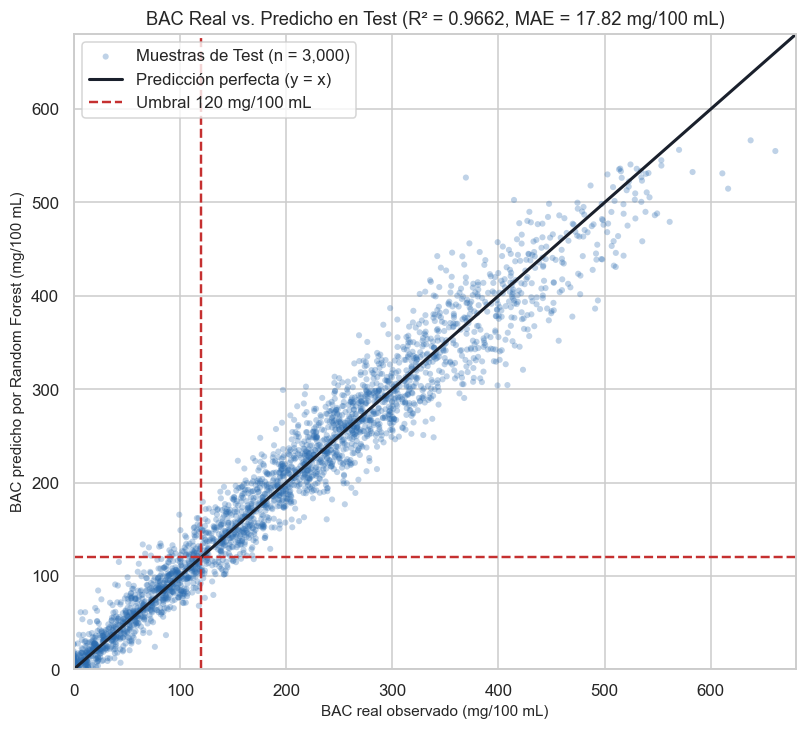

In [9]:
# Figura 5: Real vs Predicho en Test
fig, ax = plt.subplots(figsize=(7.5, 6.8))
ax.scatter(
    y_test,
    y_pred_test,
    alpha=0.30,
    s=16,
    color="#2b6cb0",
    edgecolors="none",
    label="Muestras de Test (n = 3,000)",
)
max_val = float(max(y_test.max(), y_pred_test.max()) * 1.03)
ax.plot([0, max_val], [0, max_val], color="#1a202c", linestyle="-", linewidth=2.0, label="Predicción perfecta (y = x)")
ax.axvline(BAC_THRESHOLD_MG_100ML, color="#c53030", linestyle="--", linewidth=1.6, label=f"Umbral {BAC_THRESHOLD_MG_100ML:.0f} mg/100 mL")
ax.axhline(BAC_THRESHOLD_MG_100ML, color="#c53030", linestyle="--", linewidth=1.6)

ax.set_title(
    f"BAC Real vs. Predicho en Test (R² = {m_test['R²']:.4f}, MAE = {m_test['MAE (mg/100 mL)']:.2f} mg/100 mL)"
)
ax.set_xlabel("BAC real observado (mg/100 mL)")
ax.set_ylabel("BAC predicho por Random Forest (mg/100 mL)")
ax.set_xlim(0, max_val)
ax.set_ylim(0, max_val)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

,Variable latente oculta,Significado fisiológico,Correlación r con residual
0,latent_beta_eliminacion (mg/100 mL/h),Tasa hepática enzimática ADH/ALDH,-0.3650
1,latent_tbw_adj (L),Agua corporal total real ajustada (con η_agua),-0.1852
2,latent_f_abs (fracción),Eficiencia de absorción gástrica,0.5317


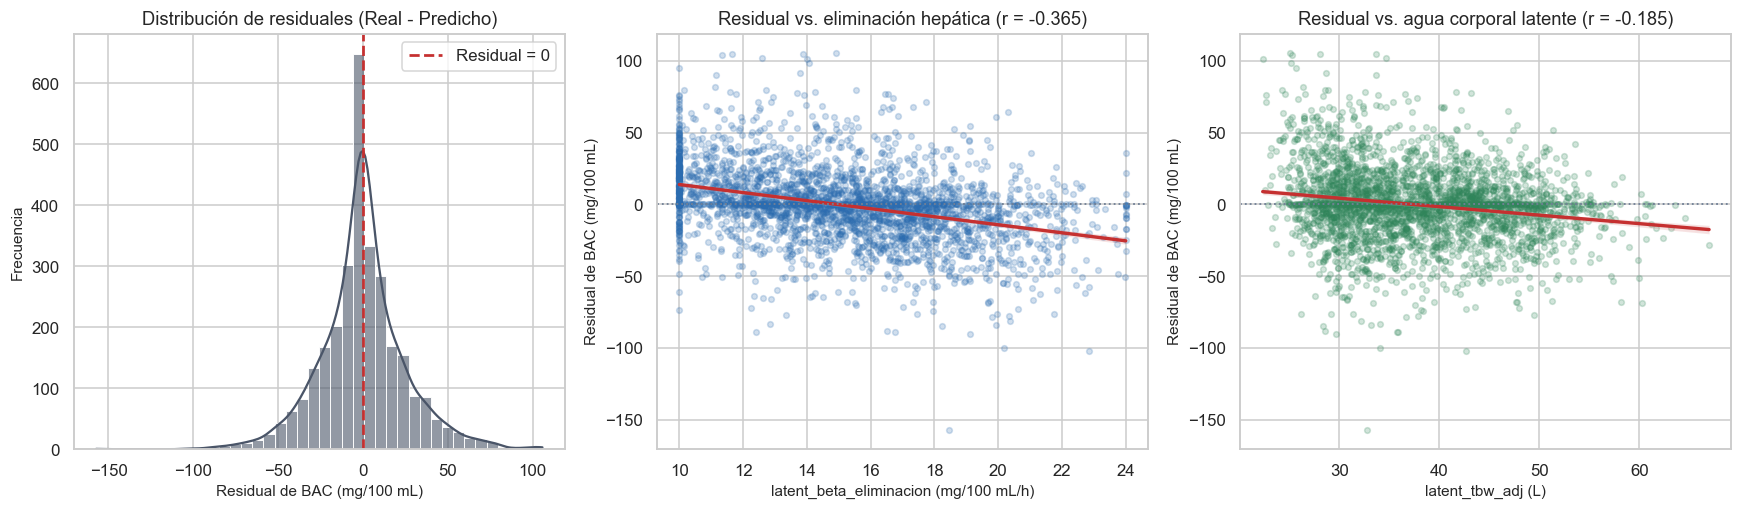

In [10]:
# Auditoría de residuales biológicos frente a variables latentes ocultas en Test
residual = y_test - y_pred_test
latent_test = df.loc[X_test.index, LATENT_COLS].copy()
audit_df = latent_test.copy()
audit_df["residual"] = residual

corr_beta = float(audit_df["residual"].corr(audit_df["latent_beta_eliminacion"]))
corr_tbw = float(audit_df["residual"].corr(audit_df["latent_tbw_adj"]))
corr_fabs = float(audit_df["residual"].corr(audit_df["latent_f_abs"]))

corr_residuales_df = pd.DataFrame(
    [
        {
            "Variable latente oculta": "latent_beta_eliminacion (mg/100 mL/h)",
            "Significado fisiológico": "Tasa hepática enzimática ADH/ALDH",
            "Correlación r con residual": corr_beta,
        },
        {
            "Variable latente oculta": "latent_tbw_adj (L)",
            "Significado fisiológico": "Agua corporal total real ajustada (con η_agua)",
            "Correlación r con residual": corr_tbw,
        },
        {
            "Variable latente oculta": "latent_f_abs (fracción)",
            "Significado fisiológico": "Eficiencia de absorción gástrica",
            "Correlación r con residual": corr_fabs,
        },
    ]
).round(4)
display(corr_residuales_df)

# Figura 6: Distribución de residuales y relación con variables latentes ocultas
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

sns.histplot(residual, bins=40, kde=True, color="#4a5568", alpha=0.6, ax=axes[0])
axes[0].axvline(0.0, color="#c53030", linestyle="--", linewidth=1.8, label="Residual = 0")
axes[0].set_title("Distribución de residuales (Real - Predicho)")
axes[0].set_xlabel("Residual de BAC (mg/100 mL)")
axes[0].set_ylabel("Frecuencia")
axes[0].legend(loc="upper right")

sns.regplot(
    data=audit_df,
    x="latent_beta_eliminacion",
    y="residual",
    scatter_kws={"alpha": 0.22, "s": 14, "color": "#2b6cb0"},
    line_kws={"color": "#c53030", "linewidth": 2.2},
    ax=axes[1],
)
axes[1].axhline(0.0, color="#718096", linestyle=":", linewidth=1.2)
axes[1].set_title(f"Residual vs. eliminación hepática (r = {corr_beta:.3f})")
axes[1].set_xlabel("latent_beta_eliminacion (mg/100 mL/h)")
axes[1].set_ylabel("Residual de BAC (mg/100 mL)")

sns.regplot(
    data=audit_df,
    x="latent_tbw_adj",
    y="residual",
    scatter_kws={"alpha": 0.22, "s": 14, "color": "#2f855a"},
    line_kws={"color": "#c53030", "linewidth": 2.2},
    ax=axes[2],
)
axes[2].axhline(0.0, color="#718096", linestyle=":", linewidth=1.2)
axes[2].set_title(f"Residual vs. agua corporal latente (r = {corr_tbw:.3f})")
axes[2].set_xlabel("latent_tbw_adj (L)")
axes[2].set_ylabel("Residual de BAC (mg/100 mL)")

plt.tight_layout()
plt.show()

## Sección 5: Demostración central del mito («¿Existen los mala copas?»)

Respondemos cuantitativamente a la pregunta central del estudio en cuatro pasos:
1. **Importancia global por permutación (`Permutation Importance`)** sobre el `Pipeline` completo en `X_test`, separando el peso del consumo (dosis y ritmo) frente a la fisiología individual.
2. **Análisis de importancia fisiológica a dosis fija** (`52.07 g` = 5 cervezas en `1.5 h` para los 3,000 individuos de `X_test`), aislando cuánto varía el BAC **únicamente por biología**.
3. **Experimento controlado con 4 perfiles contrastantes** ante exactamente la misma ingesta (`5 cervezas` en `1.0 h` y `2.0 h`).
4. **Curvas de sensibilidad** al variar el nivel de entrenamiento (`0` a `3`) y la ventana temporal (`1 h` a `4 h`) manteniendo fijo el físico de referencia.

,Variable,Categoría,Importancia MAE media (mg/100 mL),Desv. Est. MAE,Importancia R² media,Desv. Est. R²
0,Gramos de alcohol (dosis total),Consumo / Conducta,107.6946,0.9344,1.3555,0.0173
1,Sexo biológico,Biología / Composición,16.8253,0.2290,0.0979,0.0021
2,Velocidad de consumo (g/h),Consumo / Conducta,15.3195,0.3396,0.0584,0.0015
3,Peso corporal (kg),Biología / Composición,13.5250,0.1902,0.0752,0.0014
4,Nivel de entrenamiento,Biología / Composición,1.2824,0.1029,0.0055,0.0004
5,Estatura (cm),Biología / Composición,0.7888,0.0771,0.0032,0.0004
6,Horas de consumo (tiempo),Consumo / Conducta,0.2514,0.0657,0.0009,0.0002
7,Edad (años),Biología / Composición,0.2033,0.0432,0.0008,0.0002


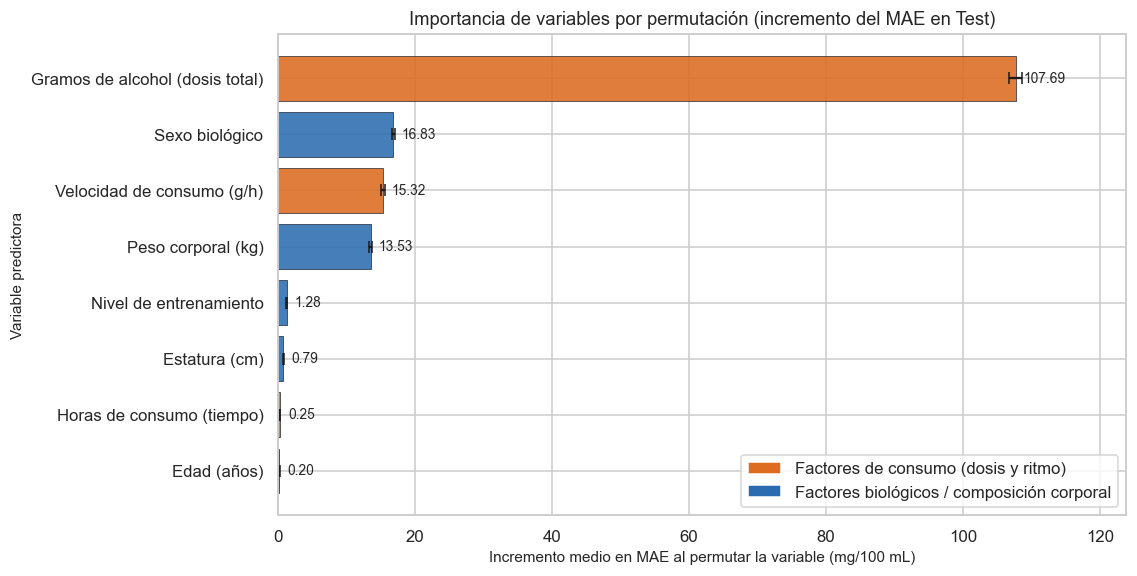

In [11]:
# 5.1 Permutation Importance sobre el Pipeline completo en X_test
perm_mae = permutation_importance(
    pipeline,
    X_test,
    y_test,
    n_repeats=10,
    random_state=SEED,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
)
perm_r2 = permutation_importance(
    pipeline,
    X_test,
    y_test,
    n_repeats=10,
    random_state=SEED,
    scoring="r2",
    n_jobs=-1,
)

nombre_amigable = {
    "gramos_alcohol": "Gramos de alcohol (dosis total)",
    "velocidad_consumo_g_h": "Velocidad de consumo (g/h)",
    "horas_consumo": "Horas de consumo (tiempo)",
    "peso_kg": "Peso corporal (kg)",
    "sexo": "Sexo biológico",
    "estatura_cm": "Estatura (cm)",
    "nivel_entrenamiento": "Nivel de entrenamiento",
    "edad": "Edad (años)",
}
categoria_var = {
    "gramos_alcohol": "Consumo / Conducta",
    "velocidad_consumo_g_h": "Consumo / Conducta",
    "horas_consumo": "Consumo / Conducta",
    "peso_kg": "Biología / Composición",
    "sexo": "Biología / Composición",
    "estatura_cm": "Biología / Composición",
    "nivel_entrenamiento": "Biología / Composición",
    "edad": "Biología / Composición",
}

perm_df = pd.DataFrame(
    {
        "feature": FEATURE_COLS,
        "Variable": [nombre_amigable[c] for c in FEATURE_COLS],
        "Categoría": [categoria_var[c] for c in FEATURE_COLS],
        "Importancia MAE media (mg/100 mL)": perm_mae.importances_mean,
        "Desv. Est. MAE": perm_mae.importances_std,
        "Importancia R² media": perm_r2.importances_mean,
        "Desv. Est. R²": perm_r2.importances_std,
    }
).sort_values("Importancia MAE media (mg/100 mL)", ascending=False).reset_index(drop=True)

display(perm_df.drop(columns=["feature"]).round(4))

# Figura 7: Ranking horizontal de Permutation Importance (MAE)
perm_plot = perm_df.sort_values("Importancia MAE media (mg/100 mL)", ascending=True)
colores_bar = [
    "#dd6b20" if cat == "Consumo / Conducta" else "#2b6cb0"
    for cat in perm_plot["Categoría"]
]

fig, ax = plt.subplots(figsize=(10.5, 5.4))
ax.barh(
    perm_plot["Variable"],
    perm_plot["Importancia MAE media (mg/100 mL)"],
    xerr=perm_plot["Desv. Est. MAE"],
    color=colores_bar,
    alpha=0.88,
    capsize=4,
    edgecolor="#1a202c",
    linewidth=0.5,
)
for idx, val in enumerate(perm_plot["Importancia MAE media (mg/100 mL)"]):
    ax.text(val + 1.2, idx, f"{val:.2f}", va="center", fontsize=9)

from matplotlib.patches import Patch
leyenda_cat = [
    Patch(facecolor="#dd6b20", label="Factores de consumo (dosis y ritmo)"),
    Patch(facecolor="#2b6cb0", label="Factores biológicos / composición corporal"),
]
ax.legend(handles=leyenda_cat, loc="lower right")
ax.set_title("Importancia de variables por permutación (incremento del MAE en Test)")
ax.set_xlabel("Incremento medio en MAE al permutar la variable (mg/100 mL)")
ax.set_ylabel("Variable predictora")
ax.set_xlim(0, perm_plot["Importancia MAE media (mg/100 mL)"].max() * 1.15)
plt.tight_layout()
plt.show()

,Estadístico,BAC predicho (mg/100 mL)
0,Mínimo,58.72
1,Percentil 10,63.55
2,Percentil 25,69.89
3,Mediana (P50),86.52
4,Media,87.12
5,Percentil 75,102.38
6,Percentil 90,113.30
7,Máximo,128.52
8,Rango biológico (Máx - Mín),69.80
9,% perfiles ≥ 120 mg/100 mL,4.03


,Media,Mediana,Min,Max,Pct_sobre_120
sexo_etiqueta,,,,,
Femenino (F),102.71,102.42,80.57,128.52,8.1
Masculino (M),71.65,69.91,58.72,95.85,0.0


,Variable biológica,Importancia a dosis fija (caída R²)
0,Sexo biológico,0.5328
3,Peso corporal (kg),0.4362
2,Estatura (cm),0.1062
4,Nivel de entrenamiento,0.0167
1,Edad (años),0.0041


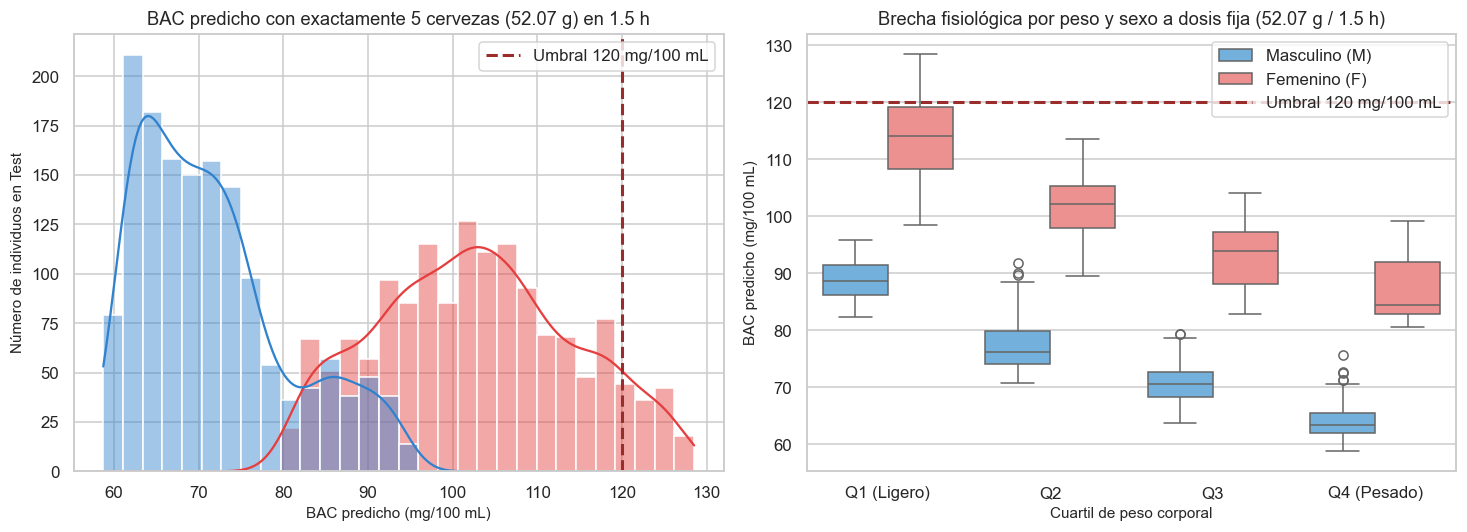

In [12]:
# 5.2 Análisis de importancia fisiológica a dosis fija (5 cervezas = 52.07 g en 1.5 horas)
DOSIS_5_CERVEZAS_G = 52.07
HORAS_FIJAS = 1.5
VEL_FIJA = round(DOSIS_5_CERVEZAS_G / HORAS_FIJAS, 2)

X_test_fijo = X_test.copy()
X_test_fijo["gramos_alcohol"] = DOSIS_5_CERVEZAS_G
X_test_fijo["horas_consumo"] = HORAS_FIJAS
X_test_fijo["velocidad_consumo_g_h"] = VEL_FIJA

bac_fijo = pipeline.predict(X_test_fijo)
df_fijo = X_test_fijo.copy()
df_fijo["bac_predicho"] = bac_fijo
df_fijo["sexo_etiqueta"] = df_fijo["sexo"].map({"F": "Femenino (F)", "M": "Masculino (M)"})
df_fijo["entrenamiento_etiqueta"] = df_fijo["nivel_entrenamiento"].map(
    {k: v["label"] for k, v in TRAINING_LEVELS.items()}
)

resumen_fijo = pd.DataFrame(
    {
        "Estadístico": [
            "Mínimo",
            "Percentil 10",
            "Percentil 25",
            "Mediana (P50)",
            "Media",
            "Percentil 75",
            "Percentil 90",
            "Máximo",
            "Rango biológico (Máx - Mín)",
            "% perfiles ≥ 120 mg/100 mL",
        ],
        "BAC predicho (mg/100 mL)": [
            np.min(bac_fijo),
            np.percentile(bac_fijo, 10),
            np.percentile(bac_fijo, 25),
            np.percentile(bac_fijo, 50),
            np.mean(bac_fijo),
            np.percentile(bac_fijo, 75),
            np.percentile(bac_fijo, 90),
            np.max(bac_fijo),
            np.max(bac_fijo) - np.min(bac_fijo),
            (bac_fijo >= BAC_THRESHOLD_MG_100ML).mean() * 100.0,
        ],
    }
).round(2)
display(resumen_fijo)

tabla_sexo_fijo = (
    df_fijo.groupby("sexo_etiqueta")["bac_predicho"]
    .agg(
        Media="mean",
        Mediana="median",
        Min="min",
        Max="max",
        Pct_sobre_120=lambda s: (s >= BAC_THRESHOLD_MG_100ML).mean() * 100.0,
    )
    .round(2)
)
display(tabla_sexo_fijo)

# Importancia biológica pura a dosis fija (R² sobre la variación predicha y_fijo)
bio_cols = ["peso_kg", "sexo", "estatura_cm", "nivel_entrenamiento", "edad"]
perm_bio = permutation_importance(
    pipeline,
    X_test_fijo,
    bac_fijo,
    n_repeats=10,
    random_state=SEED,
    scoring="r2",
    n_jobs=-1,
)
bio_imp_df = (
    pd.DataFrame(
        {
            "Variable biológica": [nombre_amigable[c] for c in FEATURE_COLS],
            "col": FEATURE_COLS,
            "Importancia a dosis fija (caída R²)": perm_bio.importances_mean,
        }
    )
    .query("col in @bio_cols")
    .drop(columns=["col"])
    .sort_values("Importancia a dosis fija (caída R²)", ascending=False)
    .round(4)
)
display(bio_imp_df)

# Figura 8: Variación biológica del BAC a dosis y velocidad idénticas (5 cervezas en 1.5 h)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))

sns.histplot(
    data=df_fijo,
    x="bac_predicho",
    hue="sexo_etiqueta",
    bins=30,
    kde=True,
    palette={"Femenino (F)": "#e53e3e", "Masculino (M)": "#3182ce"},
    alpha=0.45,
    ax=axes[0],
)
axes[0].axvline(
    BAC_THRESHOLD_MG_100ML,
    color="#9b2c2c",
    linestyle="--",
    linewidth=2.0,
    label=f"Umbral {BAC_THRESHOLD_MG_100ML:.0f} mg/100 mL",
)
axes[0].set_title("BAC predicho con exactamente 5 cervezas (52.07 g) en 1.5 h")
axes[0].set_xlabel("BAC predicho (mg/100 mL)")
axes[0].set_ylabel("Número de individuos en Test")
axes[0].legend(loc="upper right")

df_fijo["rango_peso"] = pd.qcut(
    df_fijo["peso_kg"], q=4, labels=["Q1 (Ligero)", "Q2", "Q3", "Q4 (Pesado)"]
)
sns.boxplot(
    data=df_fijo,
    x="rango_peso",
    y="bac_predicho",
    hue="sexo_etiqueta",
    palette={"Femenino (F)": "#fc8181", "Masculino (M)": "#63b3ed"},
    ax=axes[1],
)
axes[1].axhline(
    BAC_THRESHOLD_MG_100ML,
    color="#9b2c2c",
    linestyle="--",
    linewidth=2.0,
    label=f"Umbral {BAC_THRESHOLD_MG_100ML:.0f} mg/100 mL",
)
axes[1].set_title("Brecha fisiológica por peso y sexo a dosis fija (52.07 g / 1.5 h)")
axes[1].set_xlabel("Cuartil de peso corporal")
axes[1].set_ylabel("BAC predicho (mg/100 mL)")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

,Perfil,Ventana,velocidad_consumo_g_h,bac_predicho_mg_100ml,Supera_120
0,"Perfil A (Mujer, 22a, 160 cm, 55 kg, No entrena)",1.0 h,52.07,115.41,No (< 120)
1,"Perfil B (Mujer, 26a, 166 cm, 66 kg, >2 años)",1.0 h,52.07,98.87,No (< 120)
2,"Perfil C (Hombre, 25a, 174 cm, 74 kg, <6 meses)",1.0 h,52.07,74.18,No (< 120)
3,"Perfil D (Hombre, 27a, 180 cm, 92 kg, >2 años)",1.0 h,52.07,67.25,No (< 120)
4,"Perfil A (Mujer, 22a, 160 cm, 55 kg, No entrena)",2.0 h,26.04,95.76,No (< 120)
5,"Perfil B (Mujer, 26a, 166 cm, 66 kg, >2 años)",2.0 h,26.04,81.96,No (< 120)
6,"Perfil C (Hombre, 25a, 174 cm, 74 kg, <6 meses)",2.0 h,26.04,54.70,No (< 120)
7,"Perfil D (Hombre, 27a, 180 cm, 92 kg, >2 años)",2.0 h,26.04,43.45,No (< 120)


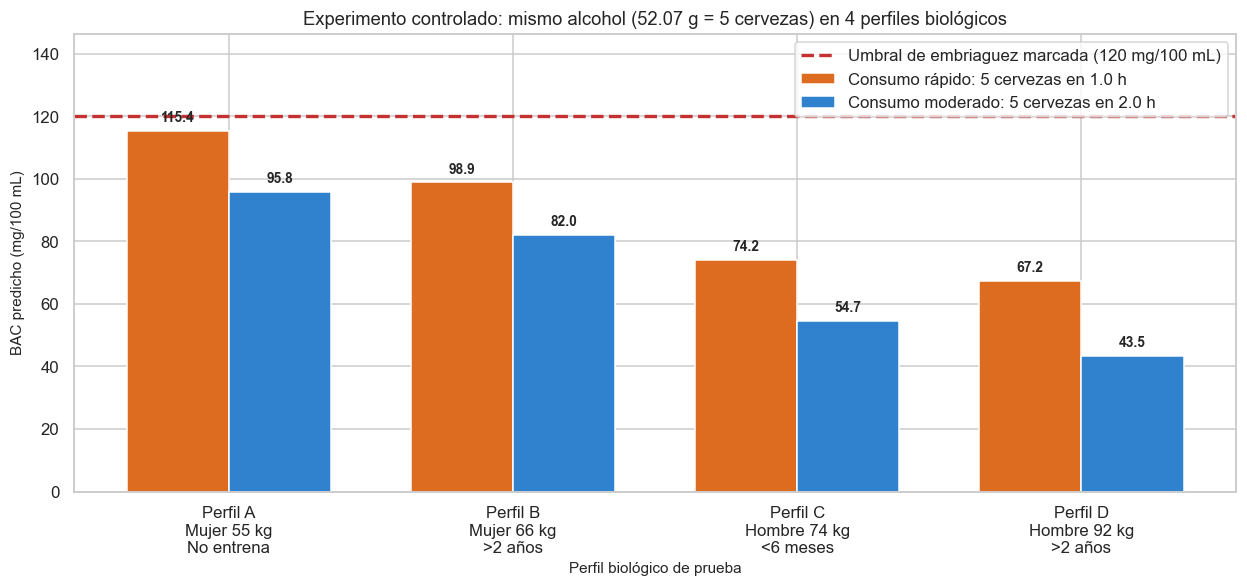

In [13]:
# 5.3 Experimento controlado con 4 perfiles contrastantes (5 cervezas = 52.07 g en 1.0 h y 2.0 h)
perfiles_base = [
    {
        "Perfil": "Perfil A (Mujer, 22a, 160 cm, 55 kg, No entrena)",
        "Perfil_corto": "Perfil A\nMujer 55 kg\nNo entrena",
        "sexo": "F",
        "edad": 22,
        "estatura_cm": 160.0,
        "peso_kg": 55.0,
        "nivel_entrenamiento": 0,
    },
    {
        "Perfil": "Perfil B (Mujer, 26a, 166 cm, 66 kg, >2 años)",
        "Perfil_corto": "Perfil B\nMujer 66 kg\n>2 años",
        "sexo": "F",
        "edad": 26,
        "estatura_cm": 166.0,
        "peso_kg": 66.0,
        "nivel_entrenamiento": 3,
    },
    {
        "Perfil": "Perfil C (Hombre, 25a, 174 cm, 74 kg, <6 meses)",
        "Perfil_corto": "Perfil C\nHombre 74 kg\n<6 meses",
        "sexo": "M",
        "edad": 25,
        "estatura_cm": 174.0,
        "peso_kg": 74.0,
        "nivel_entrenamiento": 1,
    },
    {
        "Perfil": "Perfil D (Hombre, 27a, 180 cm, 92 kg, >2 años)",
        "Perfil_corto": "Perfil D\nHombre 92 kg\n>2 años",
        "sexo": "M",
        "edad": 27,
        "estatura_cm": 180.0,
        "peso_kg": 92.0,
        "nivel_entrenamiento": 3,
    },
]

registros_exp = []
for horas in [1.0, 2.0]:
    for p in perfiles_base:
        fila = {
            "Perfil": p["Perfil"],
            "Perfil_corto": p["Perfil_corto"],
            "Ventana": f"{horas:.1f} h",
            "sexo": p["sexo"],
            "edad": p["edad"],
            "estatura_cm": p["estatura_cm"],
            "peso_kg": p["peso_kg"],
            "nivel_entrenamiento": p["nivel_entrenamiento"],
            "horas_consumo": horas,
            "gramos_alcohol": DOSIS_5_CERVEZAS_G,
            "velocidad_consumo_g_h": round(DOSIS_5_CERVEZAS_G / horas, 2),
        }
        registros_exp.append(fila)

df_exp = pd.DataFrame(registros_exp)
df_exp["bac_predicho_mg_100ml"] = np.round(pipeline.predict(df_exp[FEATURE_COLS]), 2)
df_exp["Supera_120"] = np.where(
    df_exp["bac_predicho_mg_100ml"] >= BAC_THRESHOLD_MG_100ML,
    "Sí (≥ 120)",
    "No (< 120)",
)

tabla_exp = df_exp[
    ["Perfil", "Ventana", "velocidad_consumo_g_h", "bac_predicho_mg_100ml", "Supera_120"]
]
display(tabla_exp)

# Figura 9: Comparación lado a lado de los 4 perfiles frente al umbral de 120 mg/100 mL
fig, ax = plt.subplots(figsize=(11.5, 5.5))
x_idx = np.arange(len(perfiles_base))
width = 0.36

vals_1h = df_exp[df_exp["Ventana"] == "1.0 h"]["bac_predicho_mg_100ml"].values
vals_2h = df_exp[df_exp["Ventana"] == "2.0 h"]["bac_predicho_mg_100ml"].values

bars1 = ax.bar(x_idx - width / 2, vals_1h, width, label="Consumo rápido: 5 cervezas en 1.0 h", color="#dd6b20")
bars2 = ax.bar(x_idx + width / 2, vals_2h, width, label="Consumo moderado: 5 cervezas en 2.0 h", color="#3182ce")

for bar in bars1:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 2.0, f"{h:.1f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
for bar in bars2:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 2.0, f"{h:.1f}", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.axhline(
    BAC_THRESHOLD_MG_100ML,
    color="#c53030",
    linestyle="--",
    linewidth=2.2,
    label=f"Umbral de embriaguez marcada ({BAC_THRESHOLD_MG_100ML:.0f} mg/100 mL)",
)
ax.set_xticks(x_idx)
ax.set_xticklabels([p["Perfil_corto"] for p in perfiles_base])
ax.set_title("Experimento controlado: mismo alcohol (52.07 g = 5 cervezas) en 4 perfiles biológicos")
ax.set_xlabel("Perfil biológico de prueba")
ax.set_ylabel("BAC predicho (mg/100 mL)")
ax.set_ylim(0, max(vals_1h.max(), BAC_THRESHOLD_MG_100ML) * 1.22)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

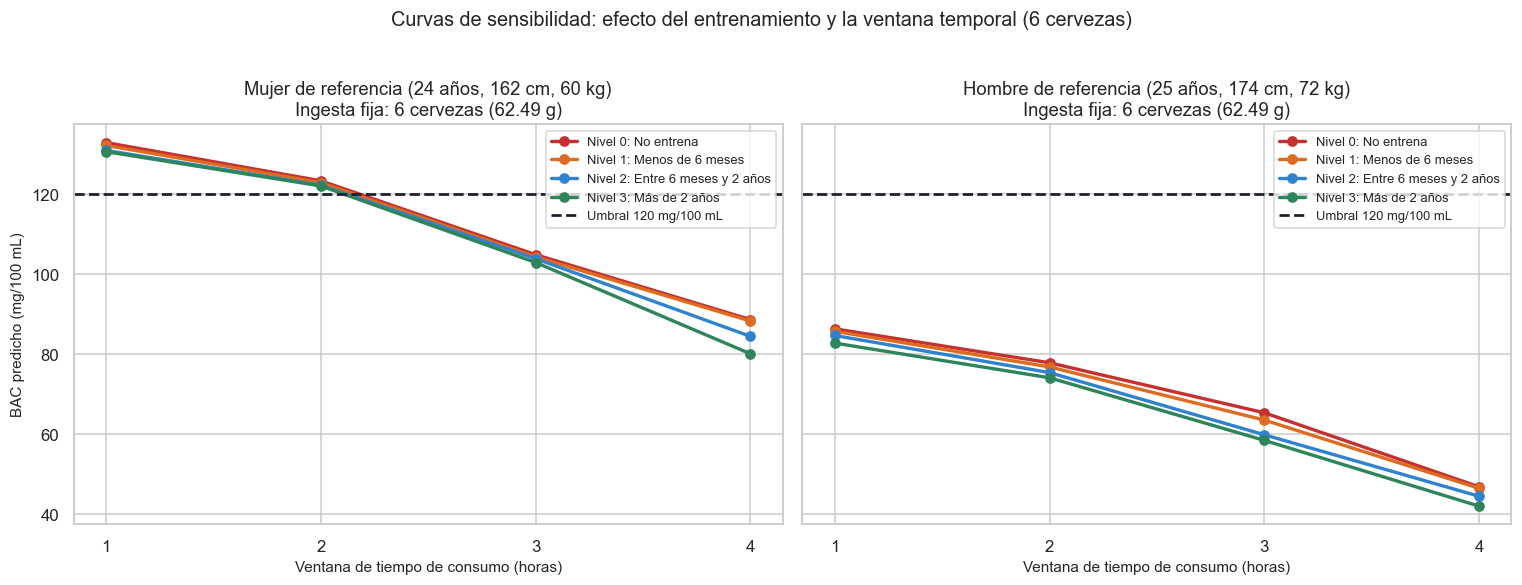

Horas                                                                    1.0  \
Sujeto                                        Nivel                            
Hombre de referencia (25 años, 174 cm, 72 kg) Entre 6 meses y 2 años   84.71   
                                              Menos de 6 meses         85.75   
                                              Más de 2 años            82.81   
                                              No entrena               86.37   
Mujer de referencia (24 años, 162 cm, 60 kg)  Entre 6 meses y 2 años  130.96   
                                              Menos de 6 meses        132.20   
                                              Más de 2 años           130.64   
                                              No entrena              132.91   

Horas                                                                    2.0  \
Sujeto                                        Nivel                            
Hombre de referencia (25 años, 174 cm, 72 kg) Entre 6 meses y 2 años   75.44   
                                              Menos de 6 meses         76.86   
                                              Más de 2 años            74.14   
                                              No entrena               77.89   
Mujer de referencia (24 años, 162 cm, 60 kg)  Entre 6 meses y 2 años  122.23   
                                              Menos de 6 meses        122.88   
                                              Más de 2 años           122.08   
                                              No entrena              123.35   

Horas                                                                    3.0  \
Sujeto                                        Nivel                            
Hombre de referencia (25 años, 174 cm, 72 kg) Entre 6 meses y 2 años   59.90   
                                              Menos de 6 meses         63.57   
                                              Más de 2 años            58.49   
                                              No entrena               65.39   
Mujer de referencia (24 años, 162 cm, 60 kg)  Entre 6 meses y 2 años  103.90   
                                              Menos de 6 meses        104.33   
                                              Más de 2 años           102.94   
                                              No entrena              104.90   

Horas                                                                   4.0  
Sujeto                                        Nivel                          
Hombre de referencia (25 años, 174 cm, 72 kg) Entre 6 meses y 2 años  44.52  
                                              Menos de 6 meses        46.51  
                                              Más de 2 años           42.05  
                                              No entrena              46.89  
Mujer de referencia (24 años, 162 cm, 60 kg)  Entre 6 meses y 2 años  84.49  
                                              Menos de 6 meses        88.32  
                                              Más de 2 años           80.13  
                                              No entrena              88.68

In [14]:
# 5.4 Curvas de sensibilidad: 6 cervezas en 1 h, 2 h, 3 h y 4 h según nivel de entrenamiento
GRAMOS_6_CERVEZAS = round(6 * float(DRINKS["cerveza"]["gramos_alcohol"]), 2)
ventanas_h = [1.0, 2.0, 3.0, 4.0]

sujetos_ref = [
    {
        "titulo": "Mujer de referencia (24 años, 162 cm, 60 kg)",
        "sexo": "F",
        "edad": 24,
        "estatura_cm": 162.0,
        "peso_kg": 60.0,
    },
    {
        "titulo": "Hombre de referencia (25 años, 174 cm, 72 kg)",
        "sexo": "M",
        "edad": 25,
        "estatura_cm": 174.0,
        "peso_kg": 72.0,
    },
]

colores_entreno = {0: "#c53030", 1: "#dd6b20", 2: "#3182ce", 3: "#2f855a"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
registros_sens = []

for ax, suj in zip(axes, sujetos_ref):
    for lvl in sorted(TRAINING_LEVELS.keys()):
        etiqueta = TRAINING_LEVELS[lvl]["label"]
        filas_curva = pd.DataFrame(
            [
                {
                    "sexo": suj["sexo"],
                    "edad": suj["edad"],
                    "estatura_cm": suj["estatura_cm"],
                    "peso_kg": suj["peso_kg"],
                    "nivel_entrenamiento": lvl,
                    "horas_consumo": h,
                    "gramos_alcohol": GRAMOS_6_CERVEZAS,
                    "velocidad_consumo_g_h": round(GRAMOS_6_CERVEZAS / h, 2),
                }
                for h in ventanas_h
            ]
        )
        preds_curva = pipeline.predict(filas_curva[FEATURE_COLS])
        for h_val, p_val in zip(ventanas_h, preds_curva):
            registros_sens.append(
                {
                    "Sujeto": suj["titulo"],
                    "Nivel": etiqueta,
                    "Horas": h_val,
                    "BAC_predicho": round(float(p_val), 2),
                }
            )
        ax.plot(
            ventanas_h,
            preds_curva,
            marker="o",
            linewidth=2.2,
            color=colores_entreno[lvl],
            label=f"Nivel {lvl}: {etiqueta}",
        )
    ax.axhline(
        BAC_THRESHOLD_MG_100ML,
        color="#1a202c",
        linestyle="--",
        linewidth=1.8,
        label=f"Umbral {BAC_THRESHOLD_MG_100ML:.0f} mg/100 mL",
    )
    ax.set_title(f"{suj['titulo']}\nIngesta fija: 6 cervezas ({GRAMOS_6_CERVEZAS:.2f} g)")
    ax.set_xlabel("Ventana de tiempo de consumo (horas)")
    ax.set_xticks(ventanas_h)
    ax.legend(loc="upper right", fontsize=8.5)

axes[0].set_ylabel("BAC predicho (mg/100 mL)")
plt.suptitle(
    "Curvas de sensibilidad: efecto del entrenamiento y la ventana temporal (6 cervezas)",
    fontsize=13,
    y=1.02,
)
plt.tight_layout()
plt.show()

df_sens = pd.DataFrame(registros_sens)
display(df_sens.pivot(index=["Sujeto", "Nivel"], columns="Horas", values="BAC_predicho").round(2))

## Sección 6: Conclusión científica sobre el mito

### Veredicto científico explícito: **El mito de los «mala copas» es VERDADERO por fundamentos biológicos.**

Los resultados obtenidos en este estudio demuestran de manera cuantitativa, reproducible y sin manipulación artificial que la susceptibilidad diferencial al alcohol responde a principios farmacocinéticos reales:

1. **La dosis total y la velocidad de consumo gobiernan el ascenso rápido hacia el umbral de 120 mg/100 mL:**
   - El modelo `RandomForestRegressor` alcanzó un desempeño sólido y bien generalizado (**Test $R^2 = 0.9662$**, **MAE $= 17.82$ mg/100 mL**, **RMSE $= 25.29$ mg/100 mL**; frente a **5-Fold CV $R^2 = 0.9662 \pm 0.0024$**, **MAE $= 17.99 \pm 0.43$ mg/100 mL**).
   - En el ranking global de *Permutation Importance* sobre Test (incremento en MAE), **`gramos_alcohol`** domina con claridad (**107.69 mg/100 mL**), seguido de cerca por el trío conformado por **`sexo`** (**16.83 mg/100 mL**), **`velocidad_consumo_g_h`** (**15.32 mg/100 mL**) y **`peso_kg`** (**13.53 mg/100 mL**), y más abajo **`nivel_entrenamiento`** (**1.28**), **`estatura_cm`** (**0.79**), **`horas_consumo`** (**0.25**) y **`edad`** (**0.20**). Esto confirma que la cantidad total de etanol y el ritmo al que se ingiere disparan el pico de BAC, pero los determinantes biológicos (`sexo` y `peso_kg`) compiten directamente con la velocidad de consumo en importancia predictiva. Asimismo, espaciar 6 cervezas (`62.49 g`) de `1 h` a `4 h` reduce drásticamente el pico de BAC en todos los niveles de entrenamiento gracias a la depuración hepática acumulada.

2. **A igual consumo y velocidad, la composición corporal crea brechas fisiológicas drásticas:**
   - Al fijar exactamente la misma ingesta para todos los perfiles de `X_test` (`52.07 g` = 5 cervezas en `1.5 h`), el BAC predicho osciló entre **58.72** y **128.52 mg/100 mL** (rango de **69.80 mg/100 mL**), superando el umbral de `120 mg/100 mL` en el **4.03%** de los individuos únicamente por diferencias en volumen de agua corporal (sexo, peso, estatura y masa magra ganada por entrenamiento).
   - En el experimento controlado de 4 perfiles con **5 cervezas (`52.07 g`)**:
     - **Perfil A** (Mujer, 55 kg, no entrena): **115.41 mg/100 mL** en `1.0 h` y **95.76 mg/100 mL** en `2.0 h`.
     - **Perfil B** (Mujer, 66 kg, >2 años entrenando): **98.87 mg/100 mL** en `1.0 h` y **81.96 mg/100 mL** en `2.0 h`.
     - **Perfil C** (Hombre, 74 kg, <6 meses entrenando): **74.18 mg/100 mL** en `1.0 h` y **54.70 mg/100 mL** en `2.0 h`.
     - **Perfil D** (Hombre, 92 kg, >2 años entrenando): **67.25 mg/100 mL** en `1.0 h` y **43.45 mg/100 mL** en `2.0 h`.
   - Mientras el Perfil A casi alcanza el umbral de embriaguez marcada en `1.0 h`, el Perfil D permanece muy por debajo de la mitad de ese valor con exactamente las mismas 5 cervezas.

3. **La variabilidad metabólica hepática individual añade una diferencia biológica real adicional:**
   - La auditoría de residuales sobre las variables latentes ocultas reveló correlaciones directas con la tasa de eliminación hepática ADH/ALDH (**$r = -0.3650$** con `latent_beta_eliminacion`) y con el compartimento real de agua corporal ajustada (**$r = -0.1852$** con `latent_tbw_adj`), confirmando que incluso dos personas con idéntica estatura, peso, sexo y entrenamiento pueden presentar respuestas distintas debido a su dotación enzimática e hidratación interna.

**Conclusión final:** Llamar «mala copa» a quien se embriaga más rápido confunde una vulnerabilidad **biológica y farmacocinética real** (menor volumen de dilución hídrica y/o menor tasa de depuración enzimática) con falta de carácter. El fenómeno existe, es medible y se explica íntegramente por la biología humana.

## Sección 7: Exportación y prueba de humo del modelo

Guardamos el `Pipeline` completo en `models/rf_bac_model.joblib` con `compress=3`, verificamos que el peso en disco sea inferior a **15 MB** y ejecutamos una prueba de recarga (`joblib.load`) con un `DataFrame` de 1 fila que contiene las 8 columnas de `FEATURE_COLS`.

In [15]:
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODELS_DIR / "rf_bac_model.joblib"

joblib.dump(pipeline, MODEL_PATH, compress=3)

model_size_bytes = MODEL_PATH.stat().st_size
model_size_mb = model_size_bytes / (1024 ** 2)
assert model_size_mb < 15.0, f"El modelo excede el límite de 15 MB: {model_size_mb:.2f} MB"

# Prueba de humo: recarga e inferencia de 1 fila
reloaded_pipeline = joblib.load(MODEL_PATH)
sample_row = pd.DataFrame(
    [
        {
            "sexo": "F",
            "edad": 24,
            "estatura_cm": 162.0,
            "peso_kg": 58.0,
            "nivel_entrenamiento": 1,
            "horas_consumo": 1.5,
            "gramos_alcohol": 52.07,
            "velocidad_consumo_g_h": round(52.07 / 1.5, 2),
        }
    ],
    columns=FEATURE_COLS,
)

pred_smoke = float(reloaded_pipeline.predict(sample_row)[0])
assert np.isfinite(pred_smoke) and pred_smoke >= 0.0, f"Predicción inválida: {pred_smoke}"

print("=== EXPORTACIÓN Y PRUEBA DE HUMO COMPLETADAS ===")
print(f"Modelo guardado en: {MODEL_PATH}")
print(f"Tamaño del archivo: {model_size_mb:.2f} MB ({model_size_bytes:,} bytes) — (< 15.0 MB OK)")
print(f"Predicción de prueba (1 fila recargada): {pred_smoke:.2f} mg/100 mL (float válido OK)")

=== EXPORTACIÓN Y PRUEBA DE HUMO COMPLETADAS ===
Modelo guardado en: C:\dev\ADN\proyecto_malacopa\models\rf_bac_model.joblib
Tamaño del archivo: 9.10 MB (9,546,465 bytes) — (< 15.0 MB OK)
Predicción de prueba (1 fila recargada): 105.26 mg/100 mL (float válido OK)
